# Baselines for single-turbine gap filling

A turbine stops reporting. Its last reading was `s` steps ago. We reconstruct its active
power `Patv` at the current step from whatever is still available. `s` is the only knob:

| `s` | gap | what is still useful |
|---|---|---|
| 1 | 10 min | the turbine's own last reading is 10 minutes old; persistence is strong |
| 6 | 1 h | own history decaying, neighbours becoming competitive |
| 36 | 6 h | own history nearly worthless; only the rest of the farm can help |

Sweeping `s` therefore covers the whole range between imputation (`s = 1`) and
forecasting (`s = 36`) without having to choose between the two framings.

**This is one of three task definitions in the project, and they are not
interchangeable.** This notebook hides *one* turbine and lets every model read the other
133 at the step being predicted. Stage D (`notebooks/04_wind_gnn.ipynb`) forecasts *all*
turbines `h` steps ahead and so cannot read any turbine at the target step. A number from
there and a number from here must never be put in the same column.

**Protocol.** Every model below is fitted and scored under identical conditions:

- **Masked turbine.** One turbine per episode. All ten of its channels are hidden from
  `t - s + 1` onwards; it may only be read at steps `<= t - s`.
- **Everything else is visible.** The other 133 turbines report normally at step `t`.
- **Scored cells.** A cell counts only if the true record is `target_valid` *and* the
  turbine's last pre-gap reading exists, so persistence and the history models are
  defined. All models see the same 40 000 episodes per `s`, so the columns are
  comparable row to row.
- **Splits.** Day-based, from `config.py`: train 1-171, val 172-196, test 197-245.
  Episodes are drawn inside a split, and the sampler reserves 144 steps of headroom --
  the longest history any model in the comparison reads -- so no input window crosses a
  split boundary. That reservation is pinned with `purge=144` rather than derived from
  the model list, so dropping a long-history model cannot silently change the episode
  set and make a later table incomparable to an earlier one.
- **Metric.** MAE and RMSE in kW. Rated power is 1500 kW; the mean target is about
  450 kW.
- **Reference.** Persistence over the whole dataset
  (`results/tables/stage_a_persistence.csv`) is 77.66 / 173.31 / 334.91 kW MAE at
  10 min / 1 h / 6 h. The test split alone is calmer than the record as a whole, so the
  numbers here are lower and the two are not interchangeable.

**No leakage.** Any farm-level aggregate is computed from reporting turbines *excluding*
the masked one. A plain farm mean would feed the answer back in at about 1/134 weight.
For the neural models the masked turbine's power channel is zeroed and its `observed`
flag cleared, which is asserted in the cell below rather than assumed.


In [1]:
import sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "src" / "windgnn").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from windgnn import config as C
from windgnn import data as D
from windgnn import baselines as B
from windgnn import spatial_nn as S

C.set_plot_style()
pd.set_option("display.width", 200)
print("repo root :", ROOT)
print("data root :", C.DATA_ROOT)


repo root : C:\Users\franc\Desktop\complexity\GraphMLAssignment
data root : C:\Users\franc\Desktop\complexity\GraphMLAssignment\SDWPF_dataset


In [2]:
t0 = time.time()
df = D.load_analysis_table()
ctx = B.build_context(df)
print(f"analysis table : {df.shape[0]:,} rows in {time.time()-t0:.1f}s")
print(f"power matrix   : {ctx.power.shape[0]:,} steps x {ctx.power.shape[1]} turbines")
print(f"reporting      : {np.isfinite(ctx.power).mean()*100:.2f}%")
print(f"target_valid   : {ctx.valid.mean()*100:.2f}%   (stage A: 76.06%)")
print(f"temp faults    : {df.is_temp_abnormal.mean()*100:.2f}%  (flagged, scrubbed to NaN)")


analysis table : 4,727,520 rows in 4.3s
power matrix   : 35,280 steps x 134 turbines
reporting      : 98.95%
target_valid   : 76.06%   (stage A: 76.06%)
temp faults    : 5.87%  (flagged, scrubbed to NaN)


### Episode counts and the graph

The power matrix is reindexed onto the full `0 .. 35279` step grid before anything else.
`pivot_table` silently drops the 264 steps where no turbine reported at all, and without
the reindex a lag of `s` steps would jump across the 37.8-hour farm-wide blackout as
though the two sides were adjacent.

The graph is the symmetrised 8-nearest-neighbour graph over turbine coordinates. `k` is
not a free choice here: at `k = 2` this farm's graph **fragments into 7 components** with
only 2 edges crossing between the six north-south columns, because every turbine's two
nearest neighbours sit in its own column (407 m apart within a column against 888 m
between them). A GNN on that graph cannot move information across the farm. `k = 4` is
the smallest value that connects it; `k = 8` gives mean degree 9.5 and 366 cross-column
edges.


In [3]:
rng = np.random.default_rng(B.RNG_SEED)
rows = []
for s in (1, 6, 36):
    for split in ("train", "val", "test"):
        ep = B.sample_episodes(ctx, split, s, None, 144, rng)
        rows.append({"silence": s, "split": split, "episodes": len(ep),
                     "turbines": int(np.unique(ep.turb).size),
                     "mean target [kW]": round(float(ep.truth(ctx).mean()), 1)})
counts = pd.DataFrame(rows)

src, dst = S.knn_edges(8)
print(f"kNN graph k=8  : {src.size} directed edges, mean degree "
      f"{src.size / C.N_TURBINES:.2f}, no self-loops: {not (src == dst).any()}")
counts


kNN graph k=8  : 1268 directed edges, mean degree 9.46, no self-loops: True


,silence,split,episodes,turbines,mean target [kW]
0,1,train,2525843,134,463.9
1,1,val,331821,134,407.0
2,1,test,679343,134,451.9
3,6,train,2523778,134,463.7
4,6,val,331089,134,407.2
5,6,test,678725,134,452.2
6,36,train,2515885,134,463.6
7,36,val,327096,134,410.0
8,36,test,674233,134,451.7


### Leakage guard

The masked turbine must not appear in its own input. For the neural models this is an
assertion, not a comment: its power channel is zero, its `observed` flag is zero, and
exactly one node per episode carries the `is_target` flag.


In [4]:
probe = B.sample_episodes(ctx, "test", 6, 2_000, 144, np.random.default_rng(0))
sc = S.Standardiser().fit(ctx)
nodes, own = S.snapshot(ctx, probe.t, probe.turb, probe.s, 12, sc)
idx = np.arange(len(probe))

assert np.all(nodes[idx, probe.turb, 0] == 0.0), "LEAK: target power channel non-zero"
assert np.all(nodes[idx, probe.turb, 1] == 0.0), "LEAK: target observed flag set"
assert np.all(nodes[idx, probe.turb, 2] == 1.0), "target flag not set"
assert nodes[:, :, 2].sum(1).max() == 1.0, "more than one target flagged"
assert np.isfinite(nodes).all() and np.isfinite(own).all(), "non-finite features"

print(f"snapshot        : nodes {nodes.shape}, own lags {own.shape}")
print(f"power scaler    : mean {sc.mean:.1f} kW, std {sc.std:.1f} kW")
print("leakage guards  : PASS")


snapshot        : nodes (2000, 134, 3), own lags (2000, 12)
power scaler    : mean 363.3 kW, std 427.7 kW
leakage guards  : PASS


## Models

| model | inputs | what it isolates |
|---|---|---|
| `climatology` | turbine id, time of day | the do-nothing floor: no knowledge of the moment |
| `farm-mean` | unweighted mean of reporting turbines | spatial signal with no weighting and no topology |
| `knn-mean k=10` | unweighted mean of the 10 nearest reporting turbines | adds topology, still no weighting |
| `persistence` | the turbine's last reading | pure temporal carry-over |
| `linear-own` | ridge on 12 of its own past readings | temporal signal only |
| `linear-peers` | ridge on all 133 other turbines at step `t` | **spatial signal only**, weighted |
| `linear-both` | own history and all peers together | the linear ceiling |
| `mlp` | the `linear-both` inputs, flattened | does non-linearity help? |
| `gnn-gatv2` | the same, 2 GATv2 hops over the kNN graph (k=8) | does a fixed topology help? |
| `transformer` | the same, full self-attention over 134 turbines | does a *learned* topology help? |
| `paper-gru` | the turbine's own 10 channels, 144 steps | non-linear temporal (Zhou et al. 2022) |

The three rungs `farm-mean` -> `knn-mean k=10` -> `linear-peers` are the comparison that
matters most for the project's thesis, because they hold the information set roughly
fixed and change only how it is combined.

`mlp`, `gnn-gatv2` and `transformer` all read **exactly** what `linear-both` reads, so
any difference between them is architecture rather than access. The Transformer is the
control the GNN needs: it is a learned fully-connected graph, which separates "a fixed
topology helps" from "looking at other turbines helps".

`paper-gru` is the Baidu KDD Cup 2022 baseline of Zhou et al., ported from PaddlePaddle
to PyTorch (`src/windgnn/paper_gru.py`) because Paddle has no Python 3.13 Windows wheel.
The port is validated against the official metric on the 142 official `final_phase_test`
cases: it scores **-47.53** (MAE 43.05 + RMSE 52.01 MW, summed over 134 turbines), which
sits where an untuned published baseline belongs -- a top-three finisher reported -45.21.
See `results/tables/paper_gru_official_protocol.csv`.

Two documented deviations in the gap-filling re-targeting: weights are shared across
turbines rather than one model per turbine, and the learning rate is 1e-3 rather than the
published 1e-4. At 1e-4 the pooled model had not converged after six epochs (validation
MSE 0.078 against 0.044 at 1e-3), which would have put a strawman in the table.


### Where the numbers come from

The three neural models cost 5.4 hours of CPU training, so this notebook does not refit
them; it reads `results/tables/baselines_all_models.csv`. The eight cheap models **are**
refitted here and compared against the stored file, which turns the CSV from an
unverifiable artifact into a checked one. The assertion below fails loudly if the stored
table and a fresh fit ever disagree by more than 0.01 kW.

Training budget for the stored neural rows: 50 000 episodes, 14 epochs, batch 128,
AdamW at 1e-3 with cosine decay, early stopping patience 3, MSE loss, seed 16. No cell
early-stopped and validation loss was still falling slowly at epoch 14, so those three
rows are a floor on what the architectures can do at a larger budget, not a ceiling.


In [5]:
res = pd.read_csv(C.TABLES_DIR / "baselines_all_models.csv")

cheap = (B.Climatology, B.Persistence, B.LinearOwn, B.LinearPeers, B.LinearBoth,
         S.NeighbourMean(), S.NeighbourMean(k=10))
t0 = time.time()
check = B.run(ctx, silences=(1, 6, 36), window=12, n_test=40_000, models=cheap,
              verbose=False, purge=144)
print(f"refitted the cheap models in {time.time()-t0:.0f}s\n")

merged = check.merge(res, on=["model", "silence"], suffixes=("_fresh", "_stored"))
assert len(merged) == len(check), "stored table is missing a refitted row"
for metric in ("MAE [kW]", "RMSE [kW]"):
    gap = (merged[f"{metric}_fresh"] - merged[f"{metric}_stored"]).abs().max()
    print(f"max |fresh - stored|  {metric:<10s} {gap:.6f} kW")
    assert gap < 0.01, f"{metric} disagrees with the stored table by {gap:.4f} kW"
print(f"\n{len(merged)} refitted rows reproduce the stored table exactly.")


refitted the cheap models in 59s

max |fresh - stored|  MAE [kW]   0.000000 kW
max |fresh - stored|  RMSE [kW]  0.000000 kW

21 refitted rows reproduce the stored table exactly.


In [6]:
ORDER = ["climatology", "farm-mean", "knn-mean k=10", "persistence", "linear-own",
         "linear-peers", "linear-both", "mlp", "gnn-gatv2", "transformer", "paper-gru"]
mae = res.pivot_table(index="model", columns="silence", values="MAE [kW]").loc[ORDER].round(2)
rmse = res.pivot_table(index="model", columns="silence", values="RMSE [kW]").loc[ORDER].round(2)
table = pd.concat({"MAE [kW]": mae, "RMSE [kW]": rmse}, axis=1)
table


MAE [kW]                 RMSE [kW]                
silence             1       6       36        1       6       36
model                                                           
climatology     369.93  370.59  369.64    446.84  447.78  446.48
farm-mean        94.47   94.41   93.17    148.19  147.21  144.02
knn-mean k=10    69.36   68.56   67.68    121.86  119.60  116.45
persistence      52.65  127.01  261.64     91.86  197.66  378.42
linear-own       59.12  149.80  296.61     92.05  198.95  360.09
linear-peers     56.13   56.18   55.18    107.45  106.73  103.41
linear-both      48.88   55.65   55.27     92.54  104.97  102.83
mlp              51.16   62.27   62.80     85.66  106.68  106.73
gnn-gatv2        48.55   58.55   58.76     85.38  105.03  104.15
transformer      49.14   59.26   60.02     83.34  104.56  105.35
paper-gru        57.63  134.42  304.90     90.24  188.89  376.29

### Figure

Eleven series cannot share two axes: four mutually distinguishable hues do not survive
the all-pairs colour-vision check (blue against purple is Delta E 4.5 under deuteranopia,
red against green 6.8, where 8 is the target). So the figure is faceted by model family
instead -- one hue per panel, members separated by line style -- which removes the
cross-family colour comparison entirely. The y axis is logarithmic and shared across each
row, so panels are directly comparable and the flat-versus-collapsing contrast is the
visible feature.


saved: C:\Users\franc\Desktop\complexity\GraphMLAssignment\results\figures\baselines_gapfill.png


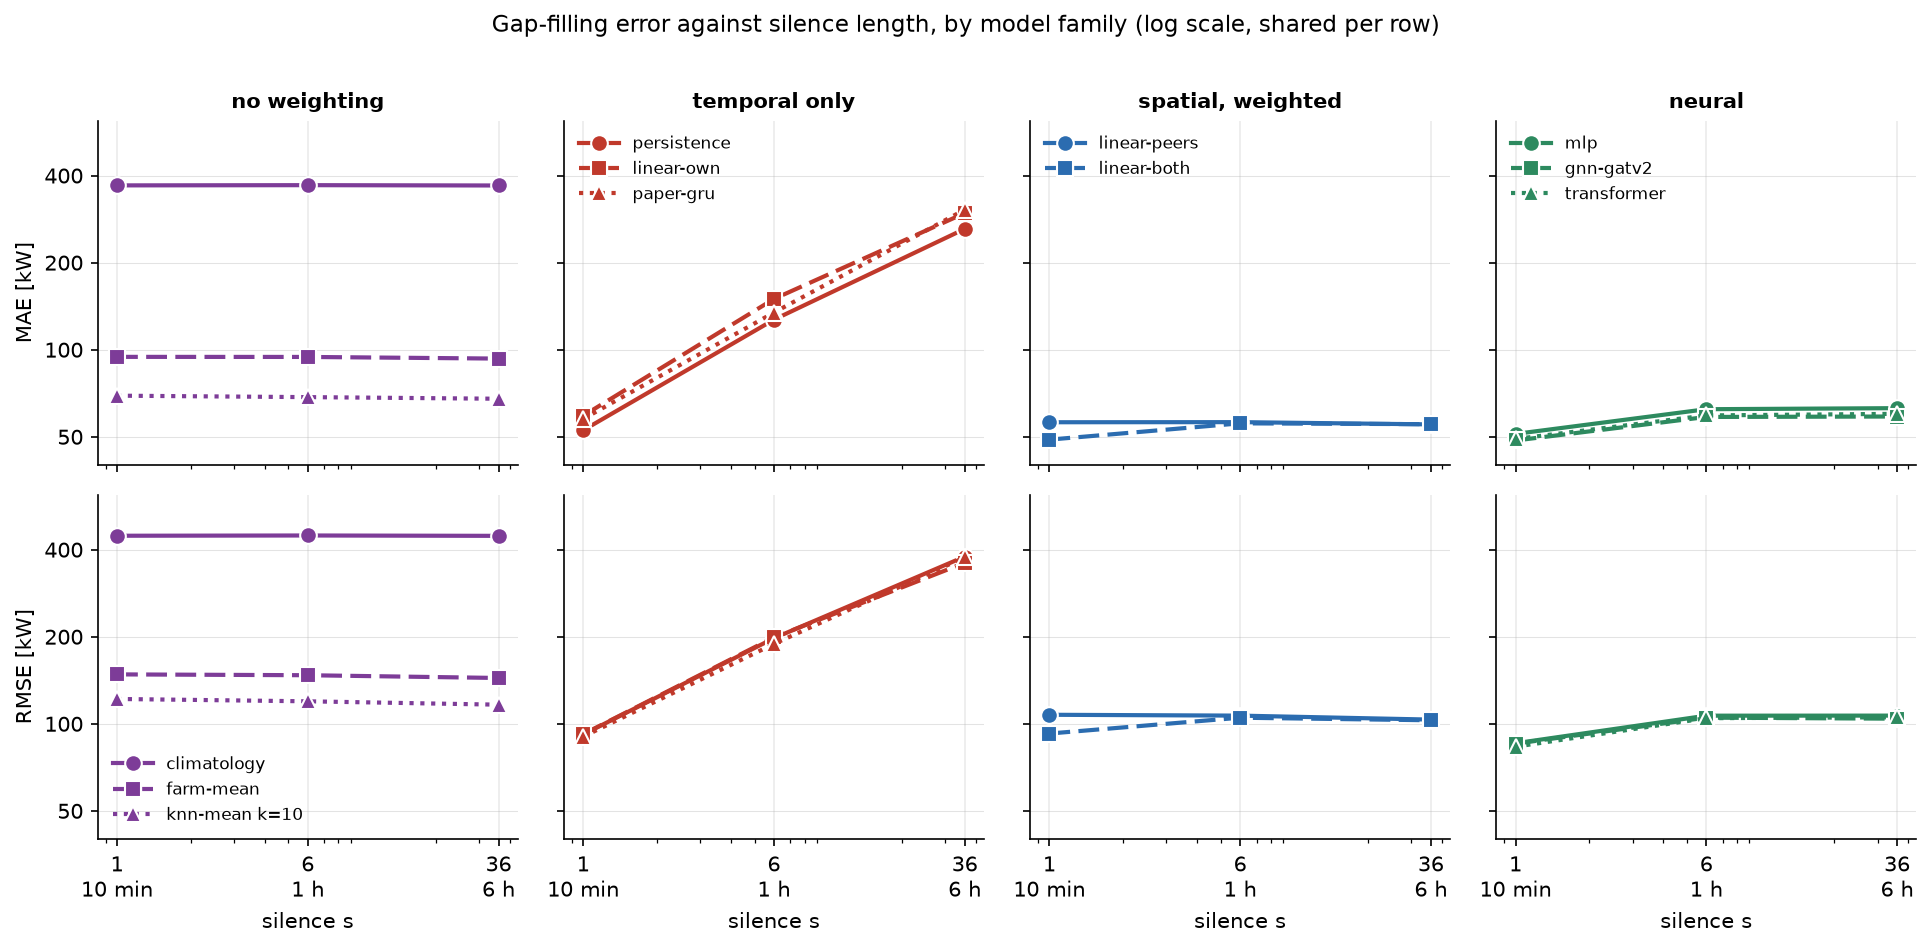

In [7]:
from matplotlib.ticker import FixedFormatter, FixedLocator, NullLocator

FAMILIES = [
    ("no weighting",      "#7d3c98", ["climatology", "farm-mean", "knn-mean k=10"]),
    ("temporal only",     "#c0392b", ["persistence", "linear-own", "paper-gru"]),
    ("spatial, weighted", "#2b6cb0", ["linear-peers", "linear-both"]),
    ("neural",            "#2d8a5f", ["mlp", "gnn-gatv2", "transformer"]),
]
DASHES = [(None, None), (5, 2), (1, 1.6)]
MARKERS = ["o", "s", "^"]
TICKS = [50, 100, 200, 400]

fig, axes = plt.subplots(2, 4, figsize=(13.0, 6.4), sharex=True, sharey="row")
for col, (fam, hue, members) in enumerate(FAMILIES):
    for row, metric in enumerate(["MAE [kW]", "RMSE [kW]"]):
        ax = axes[row, col]
        for i, name in enumerate(members):
            sub = res[res.model == name].sort_values("silence")
            ax.plot(sub.silence, sub[metric], color=hue, lw=2.0, ms=8,
                    marker=MARKERS[i], dashes=DASHES[i], label=name,
                    markeredgecolor="white", markeredgewidth=1.0, zorder=3)
        ax.set_yscale("log")
        # matplotlib's log formatter relabels the minor ticks as 3 x 10^2 and friends,
        # which overwrites the plain labels below -- silence the minor ticks entirely.
        ax.yaxis.set_major_locator(FixedLocator(TICKS))
        ax.yaxis.set_major_formatter(FixedFormatter([str(t) for t in TICKS]))
        ax.yaxis.set_minor_locator(NullLocator())
        ax.set_ylim(40, 620)
        ax.grid(True, which="major", axis="y", lw=0.5, alpha=0.35, zorder=0)
        # Both rows of a column show the same three models, so one legend per column is
        # enough -- drawn in whichever row has empty space. Column 0 spans the full range
        # in the MAE row, so its legend goes in the RMSE row instead.
        if (row, col) == (1, 0):
            ax.legend(frameon=False, fontsize=8, handlelength=2.4, loc="lower left")
        elif row == 0 and col > 0:
            ax.legend(frameon=False, fontsize=8, handlelength=2.4, loc="upper left")
        if row == 0:
            ax.set_title(fam, fontsize=10)
        if row == 1:
            ax.set_xscale("log")
            ax.set_xticks([1, 6, 36])
            ax.set_xticklabels(["1\n10 min", "6\n1 h", "36\n6 h"])
            ax.set_xlabel("silence s")
        if col == 0:
            ax.set_ylabel(metric)
fig.suptitle("Gap-filling error against silence length, by model family "
             "(log scale, shared per row)", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.97))
print("saved:", C.save_figure(fig, "baselines_gapfill"))
plt.show()


### The competitive band

The figure above is on a log axis spanning 40 to 620 kW, which is what it takes to show
the temporal models collapsing -- but it flattens the 48 to 63 kW band where the models
that actually compete are separated by two or three kW. This second figure drops to a
linear axis over that band. Everything above 110 kW is off-scale by construction.


saved: C:\Users\franc\Desktop\complexity\GraphMLAssignment\results\figures\baselines_gapfill_band.png


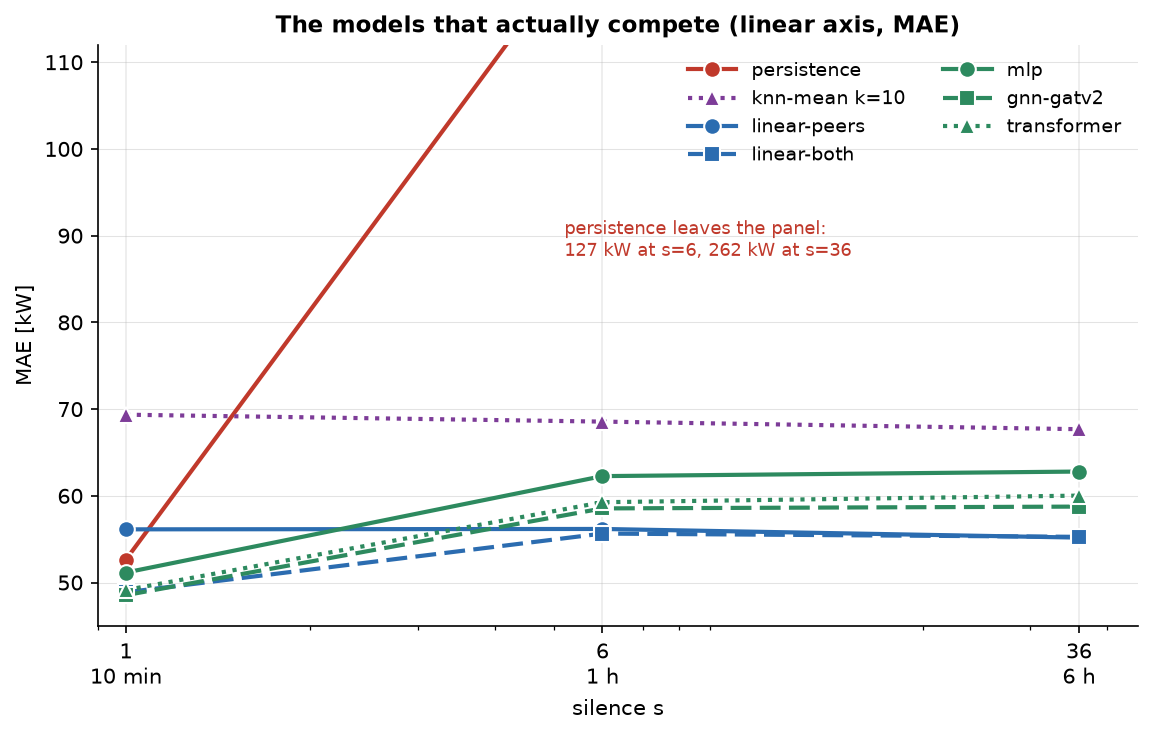

In [8]:
BAND = [
    ("persistence",   "#c0392b", (None, None), "o"),
    ("knn-mean k=10", "#7d3c98", (1, 1.6),     "^"),
    ("linear-peers",  "#2b6cb0", (None, None), "o"),
    ("linear-both",   "#2b6cb0", (5, 2),       "s"),
    ("mlp",           "#2d8a5f", (None, None), "o"),
    ("gnn-gatv2",     "#2d8a5f", (5, 2),       "s"),
    ("transformer",   "#2d8a5f", (1, 1.6),     "^"),
]

fig, ax = plt.subplots(figsize=(7.8, 5.0))
for name, hue, dash, mk in BAND:
    sub = res[res.model == name].sort_values("silence")
    ax.plot(sub.silence, sub["MAE [kW]"], color=hue, lw=2.0, ms=8, marker=mk,
            dashes=dash, label=name, markeredgecolor="white", markeredgewidth=1.0,
            zorder=3)
ax.set_xscale("log")
ax.set_xticks([1, 6, 36])
ax.set_xticklabels(["1\n10 min", "6\n1 h", "36\n6 h"])
ax.set_xlim(0.9, 45)
ax.set_ylim(45, 112)
ax.set_xlabel("silence s")
ax.set_ylabel("MAE [kW]")
ax.grid(True, axis="y", lw=0.5, alpha=0.35, zorder=0)
# linear-peers and linear-both differ by 0.09 kW at s=36, so direct labels would
# overprint; with seven series the legend is the right call anyway.
ax.legend(frameon=False, fontsize=9, loc="upper right", handlelength=2.6, ncol=2)
ax.annotate("persistence leaves the panel:\n127 kW at s=6, 262 kW at s=36",
            xy=(5.2, 92), fontsize=8.5, color="#c0392b", va="top")
ax.set_title("The models that actually compete (linear axis, MAE)", fontsize=11)
fig.tight_layout()
print("saved:", C.save_figure(fig, "baselines_gapfill_band"))
plt.show()


## What the numbers say

1. **Spatial information beats temporal information as soon as the gap exceeds ten
   minutes.** `persistence` wins at `s = 1` (52.65 kW) and is beaten 2.3x by `s = 6` and
   4.7x by `s = 36`, while every spatial model is flat in `s` -- it reads the farm at step
   `t`, so it does not care how long the turbine has been silent. That crossover is the
   central mechanism behind the project's research question, and a plain ridge regression
   measures it.

2. **The bar for the GNN is the `linear-peers` row, not the persistence floor.** A ridge
   on 133 peer values holds its error flat at every gap length and is the best single
   model at `s = 36` (55.18 kW), fitted in 9 seconds. Quoting the dataset-wide
   persistence number as the thing to beat would be far too easy.

3. **How you combine the neighbours matters more than which neighbours you take.**
   At every `s`, `farm-mean` ~94 kW -> `knn-mean k=10` ~68 kW -> `linear-peers` ~56 kW.
   Restricting to the 10 nearest buys about 25 kW; learning a weight per peer on the same
   information buys another 13 kW. Unweighted neighbour means are therefore a weak proxy
   for "what a graph can do", and a cone-of-neighbours mean that barely beats a farm mean
   is evidence about averaging, not about the graph.

4. **No model beats the linear ceiling by a defensible margin.** `gnn-gatv2` edges
   `linear-both` at `s = 1` (48.55 vs 48.88 kW) but that is 0.7%, and the five-seed
   spreads measured for these same architectures elsewhere in the project were 4.35 to
   10.28 kW. At `s = 6` and `s = 36` the linear models win on MAE outright by about 3 kW.
   **This single-seed table cannot settle the question** and should not be quoted as if
   it had.

5. **The graph does appear to help, against the no-graph control.** `gnn-gatv2` beats
   `mlp` at every silence, by 2.61 / 3.72 / 4.04 kW, and beats the Transformer too. The
   sign is consistent across three independent cells, but each gap is still inside the
   seed spread above, so this needs multiple seeds before it goes in a report as a claim.

6. **MAE and RMSE disagree, and part of the disagreement is an artifact we created.**
   The three neural models win on RMSE and lose on MAE. They are trained on MSE, while
   the ridge baselines select their alpha on validation **MAE** (`_pick_alpha`), so each
   family is being scored on the metric only it was tuned for. Before concluding "linear
   wins on MAE", the networks should be retrained with an L1 or Huber objective.

7. **A non-linear temporal model does not rescue own-history-only prediction.**
   `paper-gru` sees ten channels where `linear-own` sees one, and is non-linear, yet both
   degrade steeply with `s` while the spatial models stay flat. The limit is the
   information in a single turbine's past, not the capacity of the model reading it.
